# Triplet Loss: iResNet-34 face embeddings

**Flow: image processing → model training → loss graphs and saved artifacts.**

Use the **Python (FaceGuard CUDA 13.0)** kernel. Both experiments use random iResNet-34, 112×112 RGB crops and 256-dimensional normalized embeddings. No pretrained face weights are downloaded. Full runs can take many hours. Set `SMOKE_TEST=True` for a bounded real-image code check; its outputs are isolated below the configured artifact root.

## 1. Environment and experiment settings

Use the repository's shared `.venv` environment with Python 3.14 and PyTorch CUDA 13.0. Run `scripts/setup_mtrlearn.ps1` from the repository root to install the shared requirements and register the `mtrlearn` kernel. Do not install packages into a running notebook kernel.

In [1]:
from pathlib import Path
import os
import sys
import json

START_DIRECTORY = Path.cwd().resolve()
ROOT = next((candidate for candidate in (START_DIRECTORY, *START_DIRECTORY.parents)
             if (candidate / "src" / "recognition").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from a directory inside the repository.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage
from src.recognition.identification.config import ExperimentConfig
from src.recognition.identification.augmentation import augment_training_batch
from src.recognition.identification.data import prepare_manifests, FaceDataset, PKBatchSampler, make_loader
from src.recognition.identification.models import IResNet34
from src.recognition.identification.losses import TripletMetricLoss, ArcFaceHead
from src.recognition.identification.training import configure_runtime, run_experiment, evaluate_selected
from src.recognition.identification.notebook_utils import processing_preview, pilot_runtime, smoke_prepared, smoke_config

print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "CUDA runtime:", torch.version.cuda)
if not torch.cuda.is_available():
    raise RuntimeError("Select the Python (FaceGuard CUDA 13.0) kernel before running training.")
print("GPU:", torch.cuda.get_device_name(0))

Python: /opt/anaconda3/envs/mtrlearn/bin/python
PyTorch: 2.10.0+cu130 CUDA runtime: 13.0
GPU: NVIDIA GeForce RTX 4090


/opt/anaconda3/envs/mtrlearn/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SMOKE_TEST = os.environ.get("MTRLEARN_SMOKE", "0") == "1"
RUN_FINAL_TEST = False  # Enable after fixing the final evaluation protocol.
ARTIFACTS_ROOT = Path(os.environ.get("MTRLEARN_ARTIFACTS_ROOT", str(ROOT / "artifacts" / "main-cu130-margin-0.3-gpu-aug")))
if not ARTIFACTS_ROOT.is_absolute():
    ARTIFACTS_ROOT = ROOT / ARTIFACTS_ROOT
ARTIFACTS_ROOT = ARTIFACTS_ROOT.resolve()

CONFIG = ExperimentConfig(
    method="triplet",
    data_root=ROOT / "data" / "VGGFace2",
    artifacts_root=ARTIFACTS_ROOT,
    identities_per_batch=8,
    images_per_identity=4,
    epochs=60,
    patience=3,
    margin=0.3,
    num_workers=20,
    device="cuda:1",
    amp=True,
)
DEVICE = configure_runtime(CONFIG)
display(pd.Series(CONFIG.to_dict(), name="Experiment settings"))

method                                                                triplet
data_root                   /home/anhld/AppML/Facial-Recognition---COS3008...
artifacts_root              /home/anhld/AppML/Facial-Recognition---COS3008...
embedding_dim                                                             256
identities_per_batch                                                        8
images_per_identity                                                         4
epochs                                                                     60
margin                                                                    0.3
learning_rate                                                          0.0003
minimum_learning_rate                                                0.000001
weight_decay                                                           0.0001
warmup_epochs                                                               5
gradient_clip                                                   

## 2. Image processing and identity-disjoint manifests

Verify the source catalog, hash exact duplicates, and keep one representative without deleting originals. Split original train identities into 432 train and 48 dev; original val identities become the 60-person final test. The two notebooks reuse the same seed-42 manifests, evaluation pairs and training probe. Near duplicates and identity aliases still require review; byte hashing cannot detect them.

In [3]:
prepared = prepare_manifests(
    CONFIG.data_root,
    ROOT / "artifacts" / "shared" / "manifests",
    split_seed=42,
    dev_identities=48,
    genuine_per_identity=200,
    impostor_per_identity_pair=100,
    probe_per_identity=4,
)
if SMOKE_TEST:
    prepared = smoke_prepared(prepared)
    CONFIG = smoke_config(CONFIG)
    print("SMOKE TEST: tiny real-image subsets, altered curriculum gate, bounded epochs, no accuracy claims.")

display(pd.DataFrame([
    {"split": name, "identities": frame.identity_id.nunique(), "images": len(frame)}
    for name, frame in [("train", prepared.train), ("dev", prepared.dev), ("test", prepared.test)]
]))
print("Dev pairs:", len(prepared.dev_pairs), "Test pairs:", len(prepared.test_pairs))
print("Training probe triplets:", len(prepared.probe_triplets))

,split,identities,images
0,train,432,159647
1,dev,48,16627
2,test,60,21285


Dev pairs: 122400 Test pairs: 189000
Training probe triplets: 1728


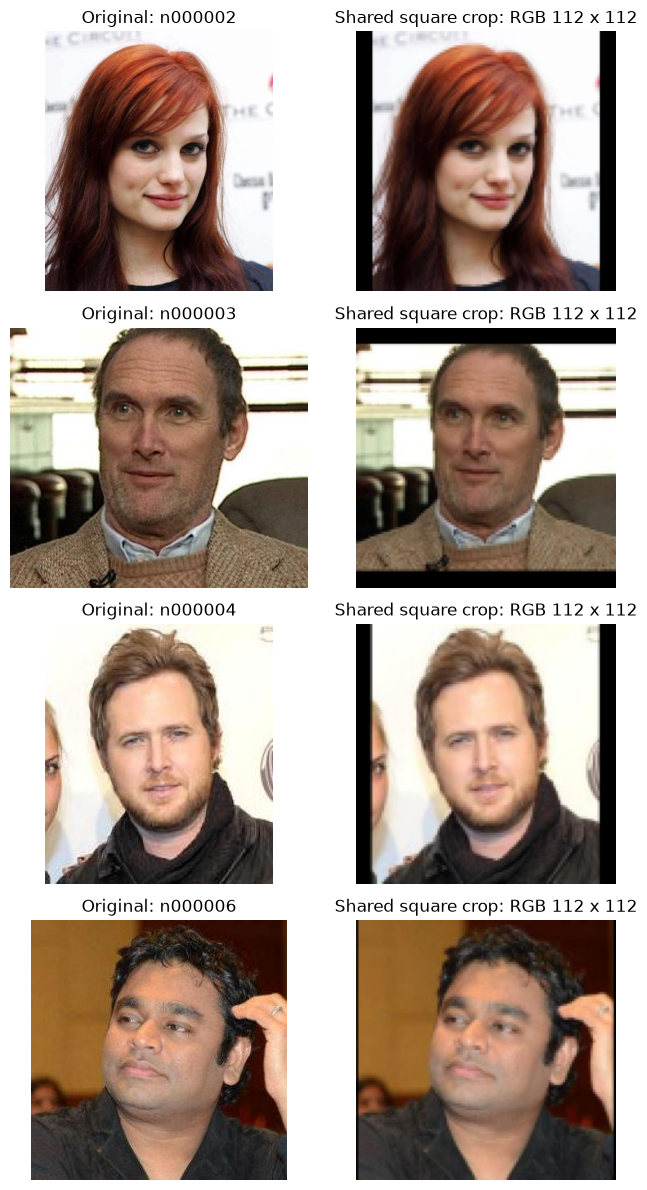

CPU decoded crops: (32, 3, 112, 112) torch.uint8 cpu
Augmented training tensor: (32, 3, 112, 112) torch.float32 cuda:1
Normalized range: -1.0 1.0
Images per identity: [4, 4, 4, 4, 4, 4, 4, 4]


In [4]:
figure = processing_preview(prepared, CONFIG.data_root, CONFIG.output_dir / "graphs" / "image_processing.png")
display(figure)
plt.close(figure)

sampler = PKBatchSampler(prepared.train.label.to_numpy(), P=CONFIG.identities_per_batch,
                         K=CONFIG.images_per_identity, batches_per_epoch=1, seed=42)
batch = next(iter(make_loader(prepared.train, CONFIG.data_root, train=True,
                              batch_sampler=sampler, num_workers=CONFIG.num_workers, seed=42)))
print("CPU decoded crops:", tuple(batch["image"].shape), batch["image"].dtype, batch["image"].device)
images = augment_training_batch(
    batch["image"].to(DEVICE, non_blocking=True),
    batch["augmentation_params"].to(DEVICE, non_blocking=True),
)
print("Augmented training tensor:", tuple(images.shape), images.dtype, images.device)
print("Normalized range:", float(images.min()), float(images.max()))
print("Images per identity:", torch.unique(batch["label"], return_counts=True)[1].tolist())
del batch, images

## 3. Model and objective

The reusable source is in `src/recognition/identification/models.py` and `losses.py`. The model uses iResNet stages [3,4,6,3], a 256-feature linear layer and final BatchNorm, followed by explicit FP32 L2 normalization. Each experiment starts from a fresh encoder initialized at seed 42. `MetricLearningTask` uses the same `Trainer.fit` engine as A/C; the backbone and loss are unchanged. The notebook retains `ExperimentConfig`, with shared engine settings adapted by `trainer_config(seed)`.

In [5]:
model = IResNet34(embedding_dim=256)
print(model)
print("Total encoder parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Trainable encoder parameters:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
del model

IResNet34(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (prelu): PReLU(num_parameters=64)
  (layer1): Sequential(
    (0): IBasicBlock(
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (prelu): PReLU(num_parameters=64)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (downsample): Sequential(
        (0): Conv2d(64, 64, kernel_size=(1, 1), stride=(2, 2), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (1): IB

B0 uses squared Euclidean Triplet Loss on unit embeddings with fixed margin **0.3**. All B(K−1) directed positive pairs form the denominator, including missing semi-hard candidates as zero. Random negatives are used first. After at least five random epochs, three consecutive fixed TRAIN probe checks must pass ranking rate ≥0.75, mean distance gap ≥0.05 and feature spread >0.001. The switch is one-way. Strict semi-hard selection has no hard-negative fallback; empty batches skip optimizer updates.

In [6]:
objective = TripletMetricLoss(margin=CONFIG.margin)
print(objective)
print("Fixed loss margin:", CONFIG.margin)
print("Squared distance: d2(a,p) = ||normalize(a) - normalize(p)||^2")

TripletMetricLoss()
Fixed loss margin: 0.3
Squared distance: d2(a,p) = ||normalize(a) - normalize(p)||^2


## 4. Common GPU memory pilot

Measure two bounded optimization steps for both objectives using disposable models, then choose a common batch profile. The preferred profile is P=8, K=4, B=32; if it runs out of GPU memory, both use P=4, K=4, B=16. The pilot never supplies learned weights to the experiment. Close other GPU jobs before running it.

In [7]:
CONFIG = pilot_runtime(CONFIG, prepared)
print("Selected common profile:", CONFIG.identities_per_batch, "x", CONFIG.images_per_identity,
      "=", CONFIG.batch_size)
display(pd.Series(json.loads((Path(CONFIG.artifacts_root) / "shared" / "runtime_pilot.json").read_text())))

Selected common profile: 8 x 4 = 32


environment                  {'python': '3.14.10 | packaged by conda-forge ...
records                      [{'method': 'triplet', 'batch_size': 32, 'pass...
environment_compatibility    {'schema': 1, 'python': '3.14', 'platform': 'L...
selected_batch_size                                                         32
P                                                                            8
K                                                                            4
scope                        Two bounded optimization steps per objective; ...
dtype: object

## 5. Model training with fixed settings

AdamW peak LR 3e-4, five-epoch warmup, cosine decay, maximum 60 epochs and early-stopping patience **3**. Train one run at seed 42 with fixed loss margin **0.3**, without a margin sweep. Verification thresholds are calibrated on dev at the configured target FMR. Twenty CPU workers decode and crop images; batches move to CUDA for augmentation, normalization and model training. The shared trainer owns backward, AMP, clipping, and optimizer updates. Early stopping retains the minimum-epoch and Triplet curriculum gates. Completed matching runs are reused; interruptions resume from the latest session's complete `last.pt` epoch. The default artifact root is `artifacts/main-cu130-margin-0.3-gpu-aug/`; set `MTRLEARN_ARTIFACTS_ROOT` before launching the kernel to choose another root. Existing private-loop checkpoints remain untouched and are not automatically resumed. Change the artifact root when changing scientific settings; incompatible training contracts are rejected. The final test is not used during this cell.

In [8]:
runs = run_experiment(CONFIG, prepared)
display(runs[["method", "margin", "seed", "stage", "best_epoch", "dev_tar", "dev_auc", "dev_eer"]])
print("Saved run:", CONFIG.output_dir / "runs.csv")

epoch 1: dev_tar=0.030208; best epoch 1


epoch 2: dev_tar=0.047917; best epoch 2


epoch 3: dev_tar=0.067292; best epoch 3


epoch 4: dev_tar=0.062292; best epoch 3


epoch 5: dev_tar=0.080312; best epoch 5


epoch 6: dev_tar=0.117188; best epoch 6


... (12 outputs left out)

epoch 19: dev_tar=0.176563; best epoch 17


epoch 20: dev_tar=0.186979; best epoch 17


,method,margin,seed,stage,best_epoch,dev_tar,dev_auc,dev_eer
0,triplet,0.3,42,fixed,17,0.192396,0.957676,0.109069


Saved run: /home/anhld/AppML/Facial-Recognition---COS30082/artifacts/main-cu130-margin-0.3-gpu-aug/triplet/runs.csv


## 6. Loss graphs and saved artifacts

Each run saves `history.csv`, loss/verification graphs, common-schema inference `best.pt`, resumable training `last.pt`, and encoder-only inference `embedding.pt` with preprocessing metadata and the dev-calibrated verification threshold. Only `last.pt` is resumable. Each fit/resume call has a unique `trainer_runs/` session; stable `weights/` files are published after success. `MetricEmbedder` loads `best.pt` or `embedding.pt` for the shared `embed(face)` interface. The experiment folder saves `runs.csv` and `selection.json` recording the fixed settings. Smoke-test outputs must never be reported as trained-model performance.

,epoch,lr,lr_weights,lr_scalars,train_loss,train_positive_pairs,train_selected_triplets,train_active_triplets,train_empty_batch,train_zero_loss_batch,...,mean_positive_distance,mean_negative_distance,candidate_coverage,probe_ranking_rate,probe_mean_gap,probe_feature_spread,probe_triplets,probe_unique_images,curriculum_not_ready,mining_signal_warning
15,16,0.000276,0.000276,0.000276,0.029976,96.0,22.789938,22.789938,0.002806,0.002806,...,0.665517,1.224537,0.237395,0.985532,1.471535,0.061749,1728,5113,False,False
16,17,0.000271,0.000271,0.000271,0.027397,96.0,21.008018,21.008018,0.003608,0.003608,...,0.650248,1.218957,0.218834,0.990741,1.525445,0.062235,1728,5113,False,False
17,18,0.000266,0.000266,0.000266,0.025038,96.0,19.177591,19.177591,0.007015,0.007015,...,0.638260,1.211762,0.199767,0.990162,1.506698,0.062141,1728,5113,False,False
18,19,0.000261,0.000261,0.000261,0.022744,96.0,17.671878,17.671878,0.009621,0.009621,...,0.629399,1.206628,0.184082,0.989005,1.527983,0.062131,1728,5113,False,False
19,20,0.000255,0.000255,0.000255,0.021179,96.0,16.525957,16.525957,0.013630,0.013630,...,0.616126,1.193880,0.172145,0.994213,1.555057,0.062245,1728,5113,False,False


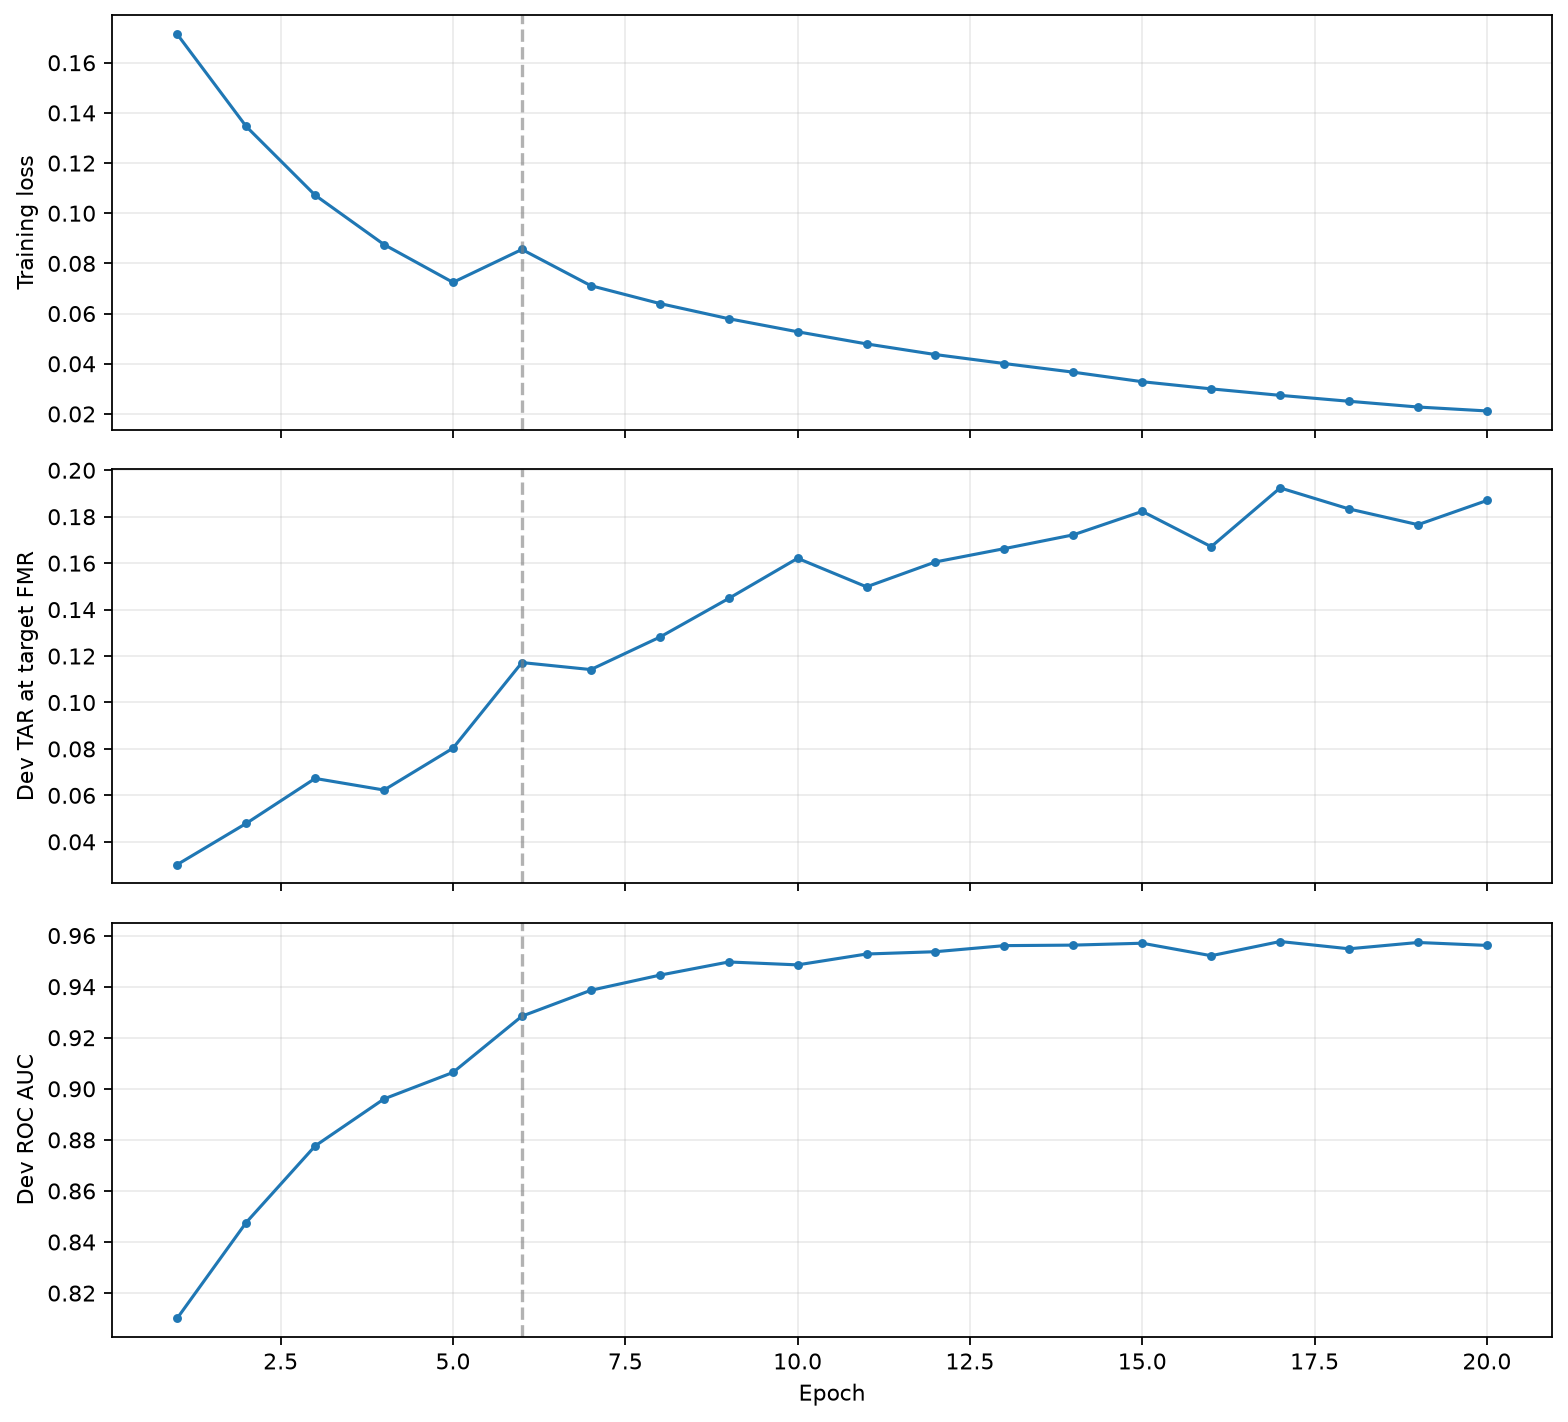

Artifact root: /home/anhld/AppML/Facial-Recognition---COS30082/artifacts/main-cu130-margin-0.3-gpu-aug/triplet
Weights:
/home/anhld/AppML/Facial-Recognition---COS30082/artifacts/main-cu130-margin-0.3-gpu-aug/triplet/runs/margin_0.3_seed_42/weights/embedding.pt


In [9]:
for run in runs.itertuples():
    history_path = Path(run.history_path)
    history = pd.read_csv(history_path)
    display(history.tail())
    display(DisplayImage(filename=str(history_path.parent / "graphs" / "loss.png")))
print("Artifact root:", CONFIG.output_dir)
print("Weights:", *sorted(str(path) for path in CONFIG.output_dir.glob("runs/*/weights/embedding.pt")), sep="\n")

## 7. Final test after checkpoint selection

Set `RUN_FINAL_TEST=True` only after fixing the evaluation protocol. This evaluates the trained checkpoint using its unchanged dev-calibrated verification threshold. Open-set gallery/probe evaluation calibrates a separate search threshold on dev and freezes it for test. The training-class head is never used for unseen-person verification.

In [10]:
if RUN_FINAL_TEST:
    test_results = evaluate_selected(CONFIG, prepared, runs)
    display(test_results)
    print("Saved:", CONFIG.output_dir / "test_results.csv")
else:
    print("Final test remains unused. Set RUN_FINAL_TEST=True after fixing the evaluation protocol.")

Final test remains unused. Set RUN_FINAL_TEST=True after fixing the evaluation protocol.


References: [iResNet source](https://github.com/deepinsight/insightface/blob/master/recognition/arcface_torch/backbones/iresnet.py), [FaceNet](https://arxiv.org/abs/1503.03832), [ArcFace](https://arxiv.org/abs/1801.07698), [OpenMMLab angular fallback](https://github.com/open-mmlab/mmpretrain/blob/main/mmpretrain/models/heads/margin_head.py).